In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
import matplotlib.patches as mpatches

In [24]:
# Plattengrenzen einlesen
ridge = gpd.read_file("./data/ridge.shp")
transform = gpd.read_file("./data/transform.shp")
trench = gpd.read_file("./data/trench.shp")

ridge["type"] = "Divergent zone"
transform["type"] = "Transform zone"
trench["type"] = "Convergent zone"

plates = gpd.GeoDataFrame(
    pd.concat(
        [
            ridge[["type", "geometry"]],
            transform[["type", "geometry"]],
            trench[["type", "geometry"]]
        ],
        ignore_index=True
    ),
    crs = ridge.crs
)

In [25]:
# Weltkarte und Erdbeben laden
crs_geo = "EPSG:4326"
world = gpd.read_file("./data/natural_earth/ne_50m_admin_0_countries.shp").to_crs(crs_geo)
world["geometry"] = world.geometry.make_valid()
quakes_df = pd.read_csv("./data/earthquake_data_tsunami.csv")

In [26]:
# Earthquake-CSV in GeoPandas umwandeln
quakes = gpd.GeoDataFrame(
    quakes_df,
    geometry=gpd.points_from_xy(quakes_df["longitude"], quakes_df["latitude"]),
    crs=crs_geo
)

In [27]:
from shapely.geometry import box
# Weltmaske als Polygon für Farbmanipulation
world_extent = gpd.GeoDataFrame(
    geometry=[box(-180, -90, 180, 90)],
    crs=crs_geo
)
ocean = gpd.overlay(world_extent, world, how="difference")

In [28]:
# In robin projektion umwandeln
crs_robin = "+proj=robin"
world_robin   = world.to_crs(crs_robin)
ocean_robin = ocean.to_crs(crs_robin)
quakes_robin  = quakes.to_crs(crs_robin)
plates_robin = plates.to_crs(crs_robin)

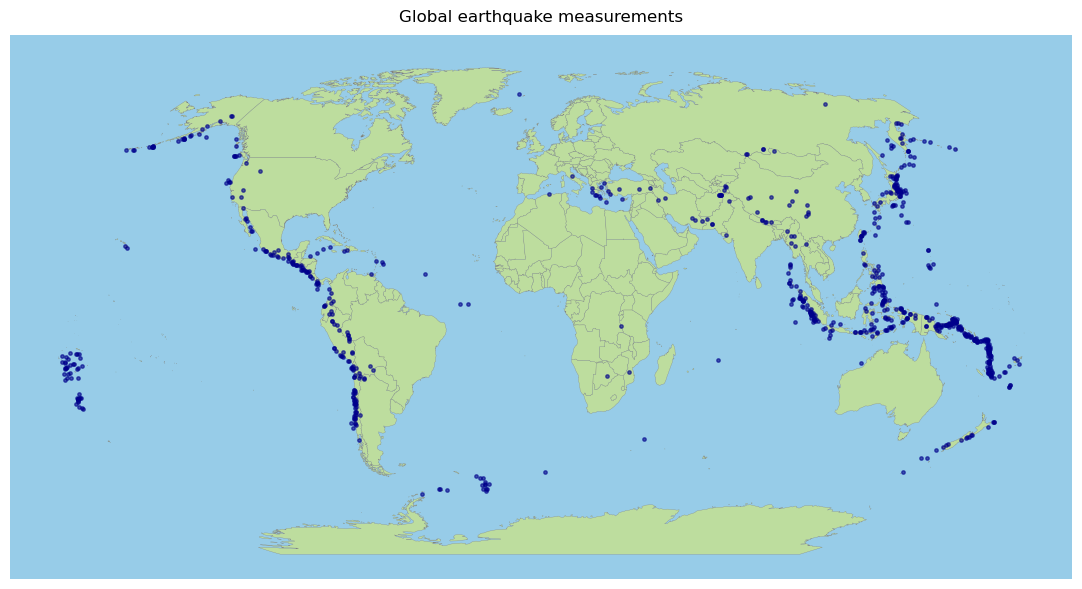

In [29]:
fix, ax = plt.subplots(figsize=(12,6), facecolor="white")
#Ozean background
ocean_robin.plot(ax=ax, color="#97cce8", zorder=0)

# Gesamten Achsenhintergrund blau machen
ax.add_patch(
    mpatches.Rectangle(
        (0, 0), 1, 1,
        transform=ax.transAxes,
        facecolor="#97cce8",
        zorder=0
    )
)

# Weltkarte
world_robin.plot(
    ax=ax,
    color="#bddd9e",
    edgecolor="grey",
    linewidth=0.2,
    zorder = 1
)
#Erdbebenpunkte
quakes_robin.plot(
    ax=ax,
    color="darkblue",
    markersize=6,
    alpha=0.6,
    zorder= 3
)

ax.set_axis_off()
ax.set_title("Global earthquake measurements", pad = 10)

plt.tight_layout()
plt.savefig(
    "pics/earthquake.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()

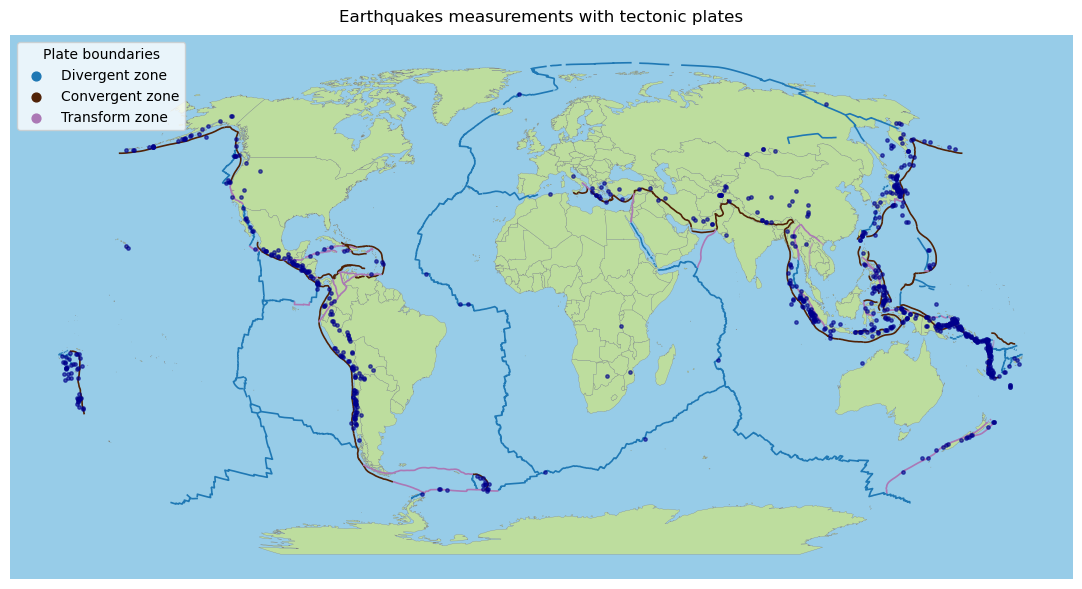

In [30]:

fix, ax = plt.subplots(figsize=(12,6), facecolor="white")

#Ozean background
ocean_robin.plot(ax=ax, color="#97cce8", zorder=0)

# Gesamten Achsenhintergrund blau machen
ax.add_patch(
    mpatches.Rectangle(
        (0, 0), 1, 1,
        transform=ax.transAxes,
        facecolor="#97cce8",
        zorder=0
    )
)

# Weltkarte
world_robin.plot(
    ax=ax,
    color="#bddd9e",
    edgecolor="grey",
    linewidth=0.2,
    zorder = 1
)

# Plattengrenzen
color_map = {
    "Divergent zone": "#1f78b4",     # blau
    "Convergent zone": "#502207",    # braun
    "Transform zone": "#ab78b5"    # violett
}
for t, c in color_map.items():
    plates_robin[plates_robin["type"] == t].plot(
        ax=ax,
        color=c,
        linewidth=1.2,
        zorder=2
    )
# 2) Dummy-Scatter für die Legende
for t, c in color_map.items():
    ax.scatter([], [], s=40, color=c, label=t)

# 3) Legende mit Punkt-Symbolen anzeigen
ax.legend(
    title="Plate boundaries",
    frameon=True,
    scatterpoints=1
)

#Erdbebenpunkte
quakes_robin.plot(
    ax=ax,
    color="darkblue",
    markersize=6,
    alpha=0.6,
    zorder= 3
)

ax.set_axis_off()
ax.set_title("Earthquakes measurements with tectonic plates", pad = 10)

plt.tight_layout()
plt.show()

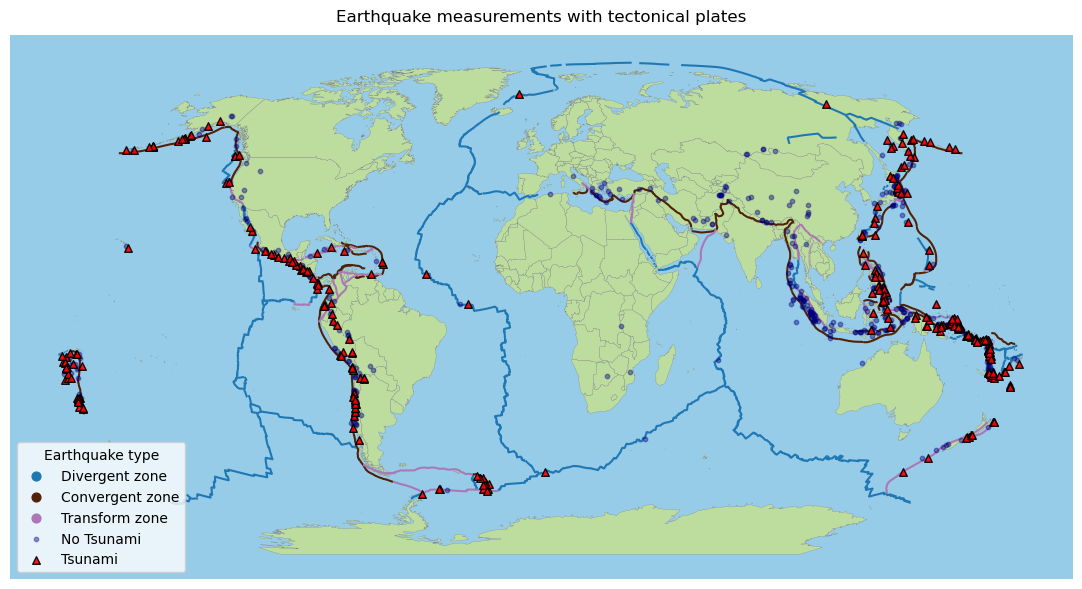

In [31]:
import matplotlib.patches as mpatches
fix, ax = plt.subplots(figsize=(12,6), facecolor="white")

#Ozean background
ocean_robin.plot(ax=ax, color="#97cce8", zorder=0)

# Gesamten Achsenhintergrund blau machen
ax.add_patch(
    mpatches.Rectangle(
        (0, 0), 1, 1,
        transform=ax.transAxes,
        facecolor="#97cce8",
        zorder=0
    )
)

# Weltkarte
world_robin.plot(
    ax=ax,
    color="#bddd9e",
    edgecolor="grey",
    linewidth=0.2,
    zorder = 1
)

# Plattengrenzen
color_map = {
    "Divergent zone": "#1f78b4",     # blau
    "Convergent zone": "#502207",    # braun
    "Transform zone": "#ab78b5"    # violett
}
for t, c in color_map.items():
    plates_robin[plates_robin["type"] == t].plot(
        ax=ax,
        color=c,
        linewidth=1.5,
        zorder=2
    )
# 2) Dummy-Scatter für die Legende
for t, c in color_map.items():
    ax.scatter([], [], s=40, color=c, label=t)

# 3) Legende mit Punkt-Symbolen anzeigen
ax.legend(
    title="Plate boundary",
    frameon=True,
    scatterpoints=1
)

# Split Daten
quakes_tsu    = quakes_robin[quakes_robin["tsunami"] == 1]
quakes_no_tsu = quakes_robin[quakes_robin["tsunami"] == 0]
# Nicht-Tsunamis
quakes_no_tsu.plot(
    ax=ax,
    color="navy",
    markersize=10,
    alpha=0.4,
    marker="o",
    label="No Tsunami",
    zorder=3
)

# Tsunamis
quakes_tsu.plot(
    ax=ax,
    color="red",
    markersize=30,
    alpha=0.9,
    marker="^",
    edgecolor="black",
    label="Tsunami",
    zorder=3.5
)

# Legende
ax.legend(title="Earthquake type")

ax.set_axis_off()
ax.set_title("Earthquake measurements with tectonical plates", pad = 10)

plt.tight_layout()
plt.savefig(
    "pics/earthquake_plateboundaries.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()

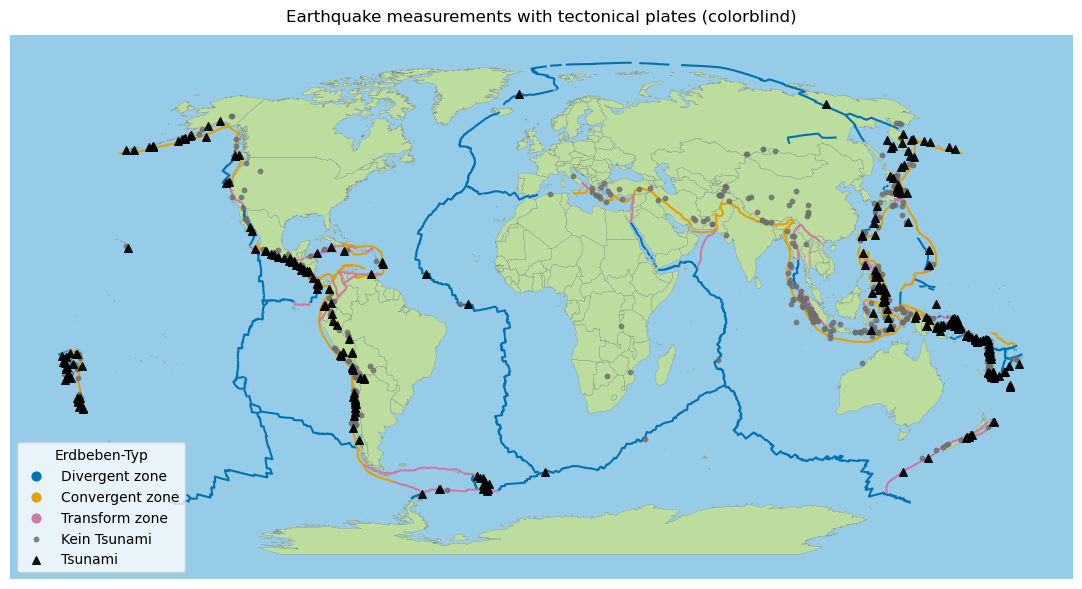

In [32]:
import matplotlib.patches as mpatches
fix, ax = plt.subplots(figsize=(12,6), facecolor="white")

#Ozean background
ocean_robin.plot(ax=ax, color="#97cce8", zorder=0)

# Gesamten Achsenhintergrund blau machen
ax.add_patch(
    mpatches.Rectangle(
        (0, 0), 1, 1,
        transform=ax.transAxes,
        facecolor="#97cce8",
        zorder=0
    )
)

# Weltkarte
world_robin.plot(
    ax=ax,
    color="#bddd9e",
    edgecolor="grey",
    linewidth=0.2,
    zorder = 1
)

# Plattengrenzen
color_map = {   #Okabe-Ito Palette
    "Divergent zone": "#0072B2",     # dunkelblaulau
    "Convergent zone": "#E69F00",    # orange mit hohem kontrast zu blau, schliesst rot-grün schwäche aus
    "Transform zone": "#CC79A7"    # violett, klar von blau und orange getrennt, auch für deutoranopie
}
for t, c in color_map.items():
    plates_robin[plates_robin["type"] == t].plot(
        ax=ax,
        color=c,
        linewidth=1.5,
        zorder=2
    )
# 2) Dummy-Scatter für die Legende
for t, c in color_map.items():
    ax.scatter([], [], s=40, color=c, label=t)

# 3) Legende mit Punkt-Symbolen anzeigen
ax.legend(
    title="Plattengrenze",
    frameon=True,
    scatterpoints=1
)

# Split Daten
quakes_tsu    = quakes_robin[quakes_robin["tsunami"] == 1]
quakes_no_tsu = quakes_robin[quakes_robin["tsunami"] == 0]
# Nicht-Tsunamis
quakes_no_tsu.plot(
    ax=ax,
    color="#6E6E6E", #dunkelgrau
    markersize=10,
    alpha=0.8,
    marker="o",
    label="Kein Tsunami",
    zorder=3
)

# Tsunamis
quakes_tsu.plot(
    ax=ax,
    color="#000000",
    markersize=30,
    alpha=0.9,
    marker="^",
    edgecolor="black",
    label="Tsunami",
    zorder=3.5
)

# Legende
ax.legend(title="Erdbeben-Typ")

ax.set_axis_off()
ax.set_title("Earthquake measurements with tectonical plates (colorblind)", pad = 10)

plt.tight_layout()
plt.savefig(
    "pics/earthquake_plateboundaries_colorblind.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()

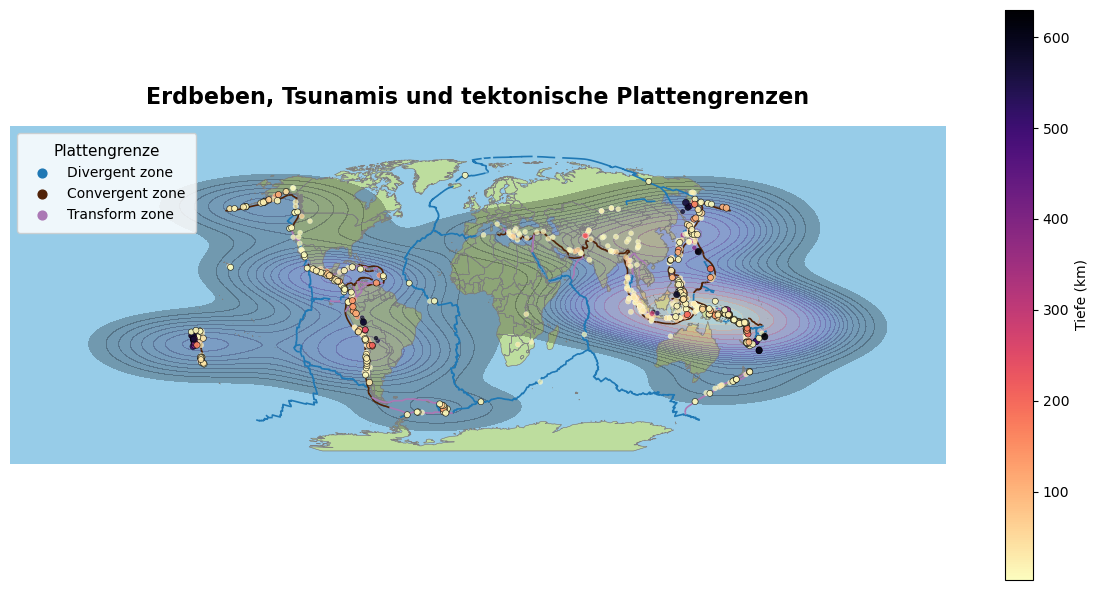

In [33]:
import matplotlib.patches as mpatches
fix, ax = plt.subplots(figsize=(12,6), facecolor="white")

#Ozean background
ocean_robin.plot(ax=ax, color="#b7dcea", zorder=0)

# Gesamten Achsenhintergrund blau machen
ax.add_patch(
    mpatches.Rectangle(
        (0, 0), 1, 1,
        transform=ax.transAxes,
        facecolor="#97cce8",
        zorder=0.5
    )
)

# Weltkarte
world_robin.plot(
    ax=ax,
    color="#bddd9e",
    edgecolor="grey",
    linewidth=0.2,
    zorder = 1
)
# Küstenlinien leicht hervorheben
world_robin.boundary.plot(
    ax=ax,
    color="grey",
    linewidth=0.4,
    zorder=1.2
)

# Plattengrenzen
color_map = {
    "Divergent zone": "#1f78b4",     # blau
    "Convergent zone": "#502207",    # braun
    "Transform zone": "#ab78b5"    # violett (neu)
}
for t, c in color_map.items():
    plates_robin[plates_robin["type"] == t].plot(
        ax=ax,
        color=c,
        linewidth=1.2,
        zorder=2
    )
# 2) Dummy-Scatter für die Legende
for t, c in color_map.items():
    ax.scatter([], [], s=40, color=c, label=t)

leg_plates = ax.legend(
    title="Plattengrenze",
    frameon=True,
    loc="upper left",
    borderpad=0.8,
    fontsize=10,
    title_fontsize=11
)
leg_plates.get_frame().set_facecolor("white")
leg_plates.get_frame().set_alpha(0.85)


sns.kdeplot(
    x=quakes_robin.geometry.x,
    y=quakes_robin.geometry.y,
    levels=20,
    fill=True,
    cmap="magma",
    alpha=0.25,
    bw_method="scott",
    ax=ax
)

# Magnitude in sinnvolle Markergrössen umrechnen
mag = quakes_robin["magnitude"]
marker_size = np.clip(mag, 4, 9)*2  # anpassen nach Geschmack

# Optional: Tsunami / Nicht-Tsunami trennen
quakes_no_tsu = quakes_robin[quakes_robin["tsunami"] == 0]
quakes_tsu    = quakes_robin[quakes_robin["tsunami"] == 1]

# Nicht-Tsunami-Beben (kleinere Marker)
quakes_no_tsu.plot(
    ax=ax,
    column="depth",
    cmap="magma_r",          # tief = hell, flach = dunkel
    markersize=marker_size[quakes_no_tsu.index],
    alpha=0.75,
    edgecolor="white",
    linewidth=0.2,
    legend=True,
    legend_kwds={"label": "Tiefe (km)"},
    zorder=3
)

# Tsunami-Beben extra und auffälliger
quakes_tsu.plot(
    ax=ax,
    column="depth",
    cmap="magma_r",
    markersize=marker_size[quakes_tsu.index] * 1.4,
    alpha=0.9,
    edgecolor="black",
    linewidth=0.4,
    marker="o",
    zorder=3.5
)

ax.set_axis_off()
ax.set_title(
    "Erdbeben, Tsunamis und tektonische Plattengrenzen",
    pad=16,
    fontsize=16,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

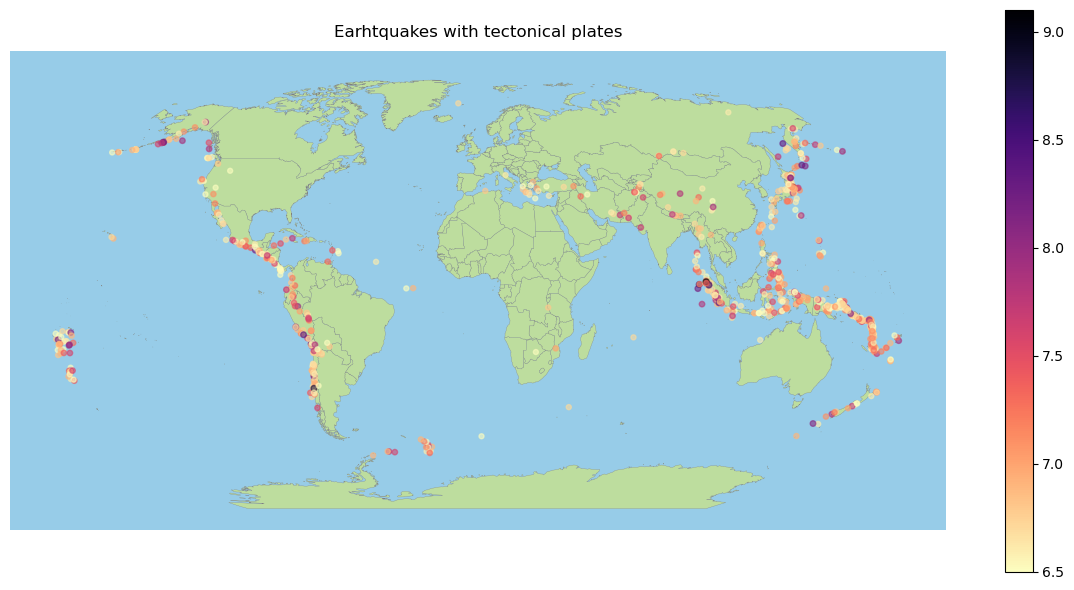

In [34]:
import matplotlib.patches as mpatches
fix, ax = plt.subplots(figsize=(12,6), facecolor="white")

#Ozean background
ocean_robin.plot(ax=ax, color="#97cce8", zorder=0)

# Gesamten Achsenhintergrund blau machen
ax.add_patch(
    mpatches.Rectangle(
        (0, 0), 1, 1,
        transform=ax.transAxes,
        facecolor="#97cce8",
        zorder=0
    )
)

# Weltkarte
world_robin.plot(
    ax=ax,
    color="#bddd9e",
    edgecolor="grey",
    linewidth=0.2,
    zorder = 1
)

#Erdbebenpunkte
quakes_robin.plot(
    ax=ax,
    column = "magnitude",
    cmap = "magma_r",
    markersize=quakes_robin["magnitude"]*2,
    legend=True,
    alpha=0.6,
    zorder= 3
)

ax.set_axis_off()
ax.set_title("Earhtquakes with tectonical plates", pad = 10)

plt.tight_layout()
plt.show()

In [35]:
# Numerische Features herausfiltern
quakes_df_num = quakes_df.select_dtypes(include=["number"])

In [36]:
corr = quakes_df_num.corr(method="pearson")
# take absolute values to sort by strength (optional)
order = corr["tsunami"].abs().sort_values(ascending=False).index.tolist()
# move "tsunami" to the end
order = [col for col in order if col != "tsunami"] + ["tsunami"]
# reorder matrix
corr_sorted = corr.loc[order, order]

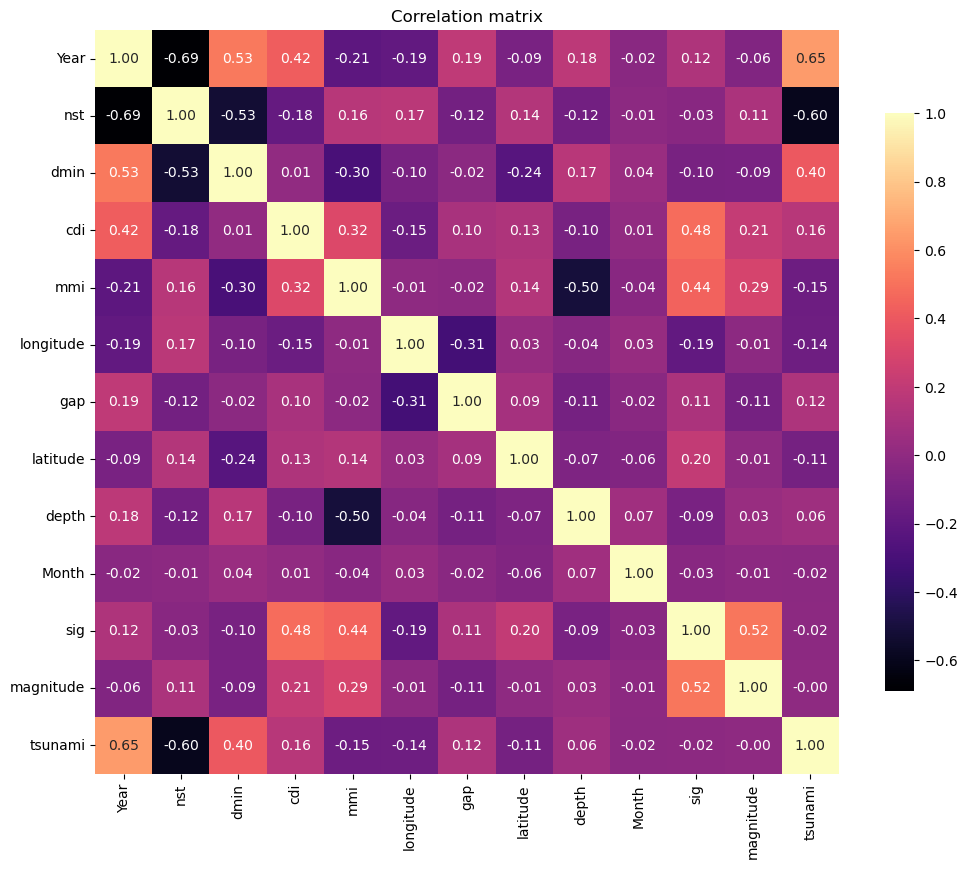

In [37]:
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_sorted,
    annot=True,         # Zahlen im Feld anzeigen
    fmt=".2f",
    cmap="magma",       
    square=True,
    cbar_kws={"shrink": .75}
)
plt.title("Correlation matrix")
plt.savefig(
    "pics/correlationmatrix.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()

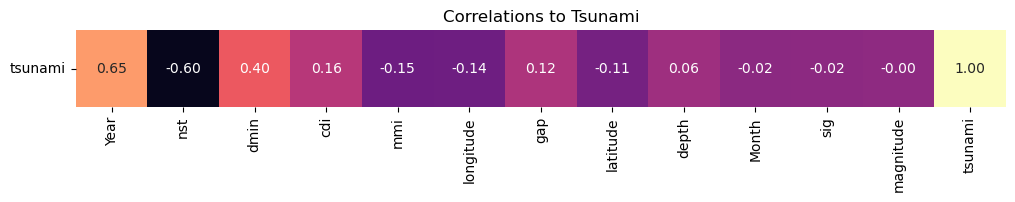

In [38]:
corr_tsunami = corr_sorted.loc[["tsunami"], :]   # Zeile behalten
plt.figure(figsize=(12, 1))
sns.heatmap(
    corr_tsunami,
    annot=True,
    fmt=".2f",
    cmap="magma",
    cbar=False,
    vmin=corr_sorted.values.min(),   
    vmax=corr_sorted.values.max()
)
plt.title("Correlations to Tsunami")
plt.xticks(rotation = 90)
plt.yticks(rotation = 0)
plt.gca().set_aspect("auto")
plt.savefig(
    "pics/Correlations_row.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()

In [39]:
from shapely.geometry import LineString
from shapely.ops import split
from shapely.affinity import translate

def shift_map_keep_attrs(shift, gdf):
    shift -= 180
    border = LineString([(shift, 90), (shift, -90)])

    out_rows = []

    for _, row in gdf.iterrows():
        geom = row.geometry
        if geom is None or geom.is_empty:
            out_rows.append(row)
            continue

        parts = split(geom, border)

        for part in parts.geoms:  
            minx, _, _, _ = part.bounds
            if minx >= shift:
                moved = translate(part, xoff=-180 - shift)
            else:
                moved = translate(part, xoff=180 - shift)

            new_row = row.copy()
            new_row.geometry = moved
            out_rows.append(new_row)

    return gpd.GeoDataFrame(out_rows, crs=gdf.crs).reset_index(drop=True)

world_pacific  = shift_map_keep_attrs(180, world)
plates_pacific = shift_map_keep_attrs(180, plates)
ocean_pacific  = shift_map_keep_attrs(180, ocean)


In [40]:
quakes_pacific = quakes.copy()

# Longitude um 180° verschieben und auf [-180, 180] normalisieren
quakes_pacific["longitude_shift"] = (quakes_pacific["longitude"] % 360) - 180

# neue Geometrie daraus bauen
quakes_pacific = quakes_pacific.set_geometry(
    gpd.points_from_xy(quakes_pacific["longitude_shift"], quakes_pacific["latitude"]),
    crs=crs_geo
)

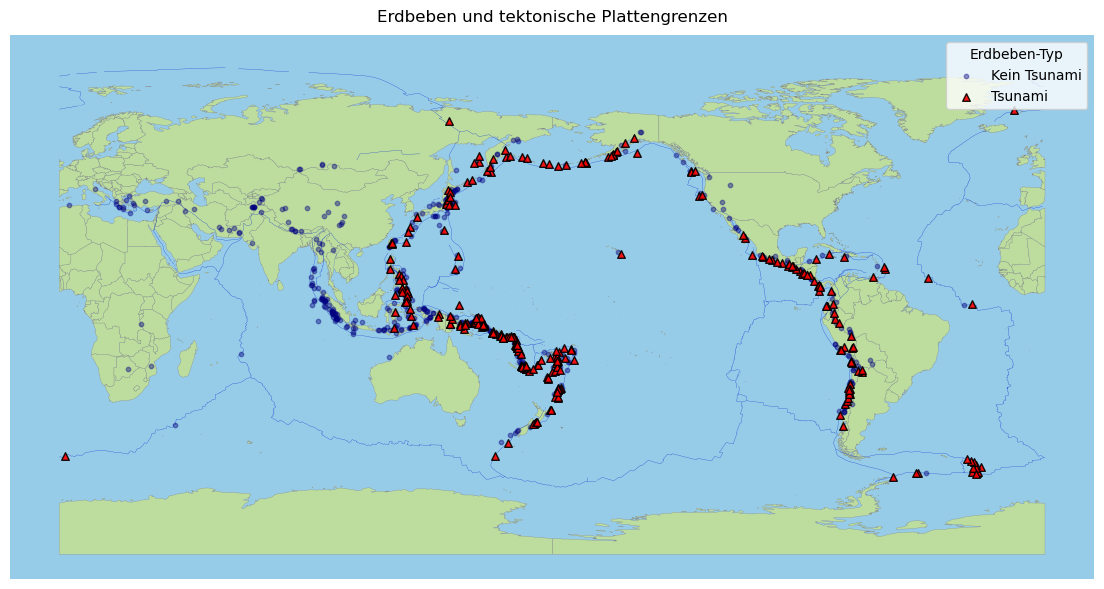

In [41]:
import matplotlib.patches as mpatches
fix, ax = plt.subplots(figsize=(12,6), facecolor="white")

# Ozean hintergrund
ocean_pacific.plot(ax=ax, color="#97cce8", zorder=0)

# Gesamten Achsenhintergrund blau machen
ax.add_patch(
    mpatches.Rectangle(
        (0, 0), 1, 1,
        transform=ax.transAxes,
        facecolor="#97cce8",
        zorder=0
    )
)

# Weltkarte
world_pacific.plot(
    ax=ax,
    color="#bddd9e",
    edgecolor="grey",
    linewidth=0.2,
    zorder = 1
)

# Plattengrenzen
plates_pacific.plot(
    ax=ax,
    color="#0c33cd",
    edgecolor="grey",
    linewidth=0.2,
    zorder = 1
)


# Split Daten
quakes_tsu    = quakes_pacific[quakes_pacific["tsunami"] == 1]
quakes_no_tsu = quakes_pacific[quakes_pacific["tsunami"] == 0]
# Nicht-Tsunamis
quakes_no_tsu.plot(
    ax=ax,
    color="navy",
    markersize=10,
    alpha=0.4,
    marker="o",
    label="Kein Tsunami",
    zorder=3
)

# Tsunamis
quakes_tsu.plot(
    ax=ax,
    color="red",
    markersize=30,
    alpha=0.9,
    marker="^",
    edgecolor="black",
    label="Tsunami",
    zorder=3.5
)

# Legende
ax.legend(title="Erdbeben-Typ")

ax.set_axis_off()
ax.set_title("Erdbeben und tektonische Plattengrenzen", pad = 10)

plt.tight_layout()
plt.show()

In [42]:
# In robinson projektion umwandeln
crs_robin = "+proj=robin"
world_pacific_robin   = world_pacific.to_crs(crs_robin)
ocean_pacific_robin = ocean_pacific.to_crs(crs_robin)
quakes_pacific_robin  = quakes_pacific.to_crs(crs_robin)
plates_pacific_robin = plates_pacific.to_crs(crs_robin)

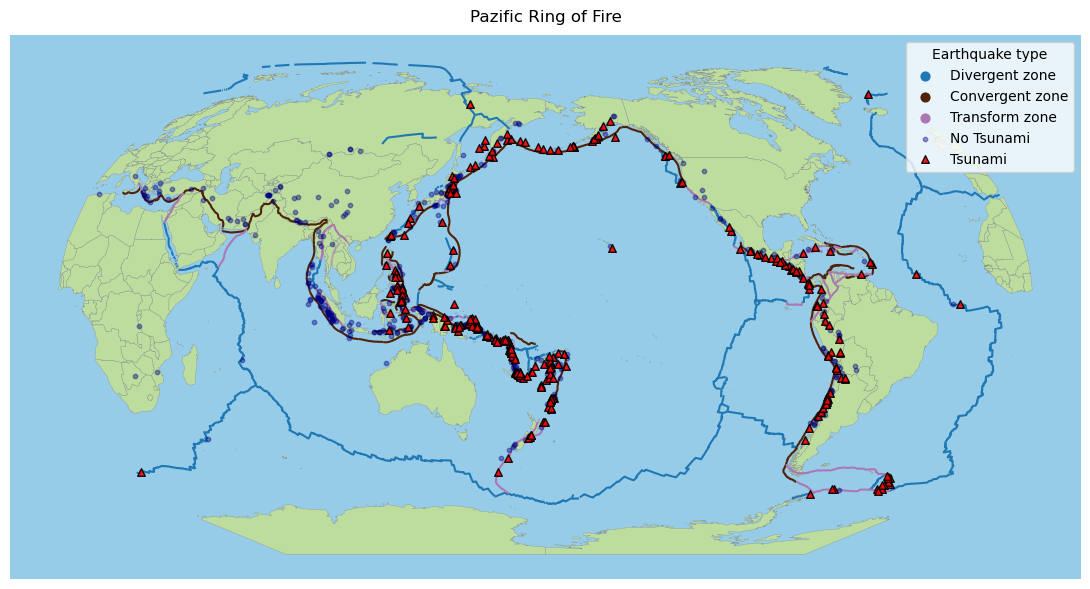

In [43]:
import matplotlib.patches as mpatches
fix, ax = plt.subplots(figsize=(12,6), facecolor="white")

# Ozean background
ocean_pacific_robin.plot(ax=ax, color="#97cce8", zorder=0)

# Gesamten Achsenhintergrund blau machen
ax.add_patch(
    mpatches.Rectangle(
        (0, 0), 1, 1,
        transform=ax.transAxes,
        facecolor="#97cce8",
        zorder=0
    )
)

# Weltkarte
world_pacific_robin.plot(
    ax=ax,
    color="#bddd9e",
    edgecolor="grey",
    linewidth=0.2,
    zorder = 1
)

# Plattengrenzen
color_map = {
    "Divergent zone": "#1f78b4",     # blau
    "Convergent zone": "#502207",    # braun
    "Transform zone": "#ab78b5"    # violett
}
for t, c in color_map.items():
    plates_pacific_robin[plates_pacific_robin["type"] == t].plot(
        ax=ax,
        color=c,
        linewidth=1.5,
        zorder=2
    )
# 2) Dummy-Scatter für die Legende
for t, c in color_map.items():
    ax.scatter([], [], s=40, color=c, label=t)

# 3) Legende mit Punkt-Symbolen anzeigen
ax.legend(
    title="Plate boundaries",
    frameon=True,
    scatterpoints=1
)

# Split Daten
quakes_tsu    = quakes_pacific_robin[quakes_pacific_robin["tsunami"] == 1]
quakes_no_tsu = quakes_pacific_robin[quakes_pacific_robin["tsunami"] == 0]
# Nicht-Tsunamis
quakes_no_tsu.plot(
    ax=ax,
    color="navy",
    markersize=10,
    alpha=0.4,
    marker="o",
    label="No Tsunami",
    zorder=3
)

# Tsunamis
quakes_tsu.plot(
    ax=ax,
    color="red",
    markersize=30,
    alpha=0.9,
    marker="^",
    edgecolor="black",
    label="Tsunami",
    zorder=3.5
)

# Legende
ax.legend(title="Earthquake type")

ax.set_axis_off()
ax.set_title("Pazific Ring of Fire", pad = 10)

plt.tight_layout()
plt.savefig(
    "pics/earthquake_pacific.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()

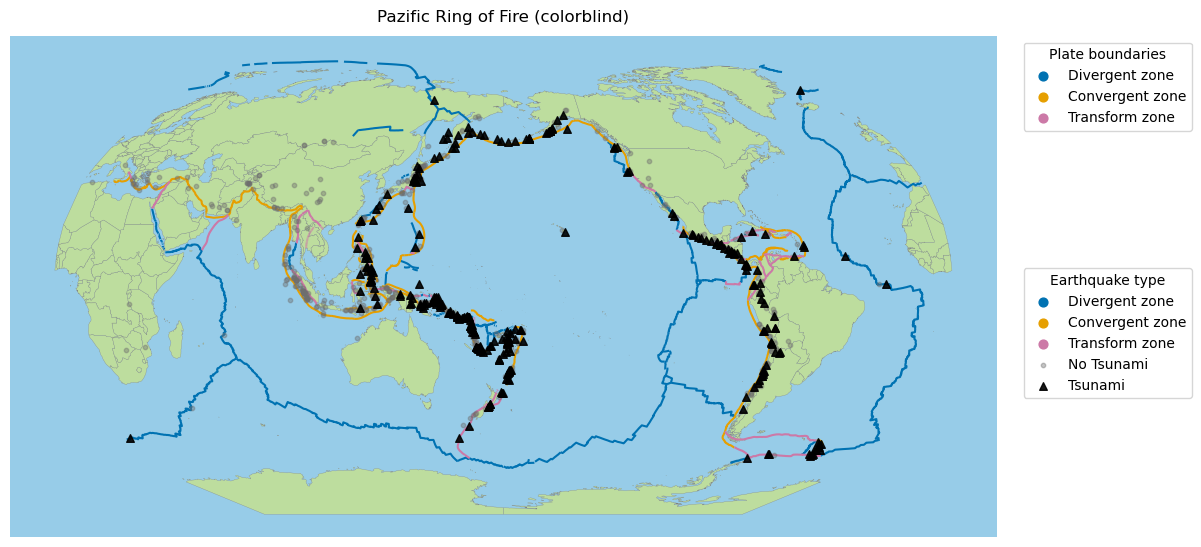

In [44]:
import matplotlib.patches as mpatches
fix, ax = plt.subplots(figsize=(12,6), facecolor="white")

# Ozean background
ocean_pacific_robin.plot(ax=ax, color="#97cce8", zorder=0)

# Gesamten Achsenhintergrund blau machen
ax.add_patch(
    mpatches.Rectangle(
        (0, 0), 1, 1,
        transform=ax.transAxes,
        facecolor="#97cce8",
        zorder=0
    )
)

# Weltkarte
world_pacific_robin.plot(
    ax=ax,
    color="#bddd9e",
    edgecolor="grey",
    linewidth=0.2,
    zorder = 1
)

# Plattengrenzen
color_map = {   #Okabe-Ito Palette
    "Divergent zone": "#0072B2",     # dunkelblaulau
    "Convergent zone": "#E69F00",    # orange mit hohem kontrast zu blau, schliesst rot-grün schwäche aus
    "Transform zone": "#CC79A7"    # violett, klar von blau und orange getrennt, auch für deutoranopie
}
for t, c in color_map.items():
    plates_pacific_robin[plates_pacific_robin["type"] == t].plot(
        ax=ax,
        color=c,
        linewidth=1.5,
        zorder=2
    )
# 2) Dummy-Scatter für die Legende
for t, c in color_map.items():
    ax.scatter([], [], s=40, color=c, label=t)

# 3) Legende mit Punkt-Symbolen anzeigen
legend_plates = ax.legend(
    title="Plate boundaries",
    frameon=True,
    scatterpoints=1,
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)
ax.add_artist(legend_plates)

# Split Daten
quakes_tsu    = quakes_pacific_robin[quakes_pacific_robin["tsunami"] == 1]
quakes_no_tsu = quakes_pacific_robin[quakes_pacific_robin["tsunami"] == 0]
# Nicht-Tsunamis
quakes_no_tsu.plot(
    ax=ax,
    color="#6E6E6E",
    markersize=10,
    alpha=0.4,
    marker="o",
    label="No Tsunami",
    zorder=3
)

# Tsunamis
quakes_tsu.plot(
    ax=ax,
    color="#000000",
    markersize=30,
    alpha=0.9,
    marker="^",
    edgecolor="black",
    label="Tsunami",
    zorder=3.5
)

# Legende
ax.legend(
    title="Earthquake type",
    loc="upper left",
    bbox_to_anchor=(1.02, 0.55)
)

ax.set_axis_off()
ax.set_title("Pazific Ring of Fire (colorblind)", pad = 10)

plt.tight_layout()
plt.savefig(
    "pics/earthquake_pacific_colorblind.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()